# 02: stationary sensor calibration

On day 1 we checked axes and onboard state estimates. In E2 we examine the bias and noise of the "Inertial Measurement Unit" (IMU). The IMU consists of three acceleromaters and three gyropscopes for the three main axes (x,y,z). There values can be obtained from the logging variables inside the drones as `acc.x,y,z` and `gyro.x.y.z`. In the exercise we will check if these readings are unbiased by monitoring their values for a stationary (not-moving) drone.

In order to use these measurements, the kalman filter inside the drone needs to know their measurement accuracy (or 'noise' in the drone laguage). We called this $\sqrt{V}$ in the lectures. The parameter values inside the drone that represents the noise values are called

|Parameter	| Default	| Interpretation|
| --- | --- | ---- |
|kalman.pNAcc_xy	| 0.5	| Horizontal acceleration noise amplitude, m/s²|
|kalman.pNAcc_z	| 1.0	| Vertical acceleration noise amplitude, m/s²
| kalman.mNGyro_rollpitch|	0.1|	Roll/pitch angular-rate noise amplitude, rad/s|
|kalman.mNGyro_yaw	|0.1	|Yaw angular-rate noise amplitude, rad/s|

All are defined in [kalman_core_params_defaults.h](https://github.com/bitcraze/crazyflie-firmware/blob/2026.08/src/modules/interface/kalman_core/kalman_core_params_defaults.h).

Record one stationary IMU sample and compare its six distributions with the noise amplitudes currently configured in the drone's Kalman filter.

In [1]:
# run this to set up the notebook environment and import shared helpers
from pathlib import Path
import sys

# Shared helpers are beside day2; data stays beside these notebooks.
notebook_dir = Path.cwd()
if (notebook_dir / "code/day2").is_dir():
    notebook_dir = notebook_dir / "code/day2"
sys.path.insert(0, str(notebook_dir.resolve().parent))

from notebook_radio import check_drone
from day2.notebook_tools import (
    capture, read_imu,
)

import time
run_id = time.strftime("e2-%Y%m%d-%H%M%S")  # A fresh folder each session, so recordings never collide.
output = notebook_dir / "data" / run_id
output.mkdir(parents=True, exist_ok=True)
print("Results:", output.resolve())

Results: /Users/casparvaneck/Desktop/crazyflie-topical-lectures/code/day2/data/e2-20261104-130040


## Connect

Put the drone on a stable surface, keep clear of propellers and close cfclient. Set `LABEL` to your drone's sticker label and run the cell. After the LEDs blink, the cell intentionally pauses for confirmation: type `yes` in the input prompt to continue. Confirm that it was your drone before proceeding. To skip only the typed prompt, pass `confirm_blink=False` to `check_drone`; the LEDs will still blink, so use this only if you verify the drone independently.


In [2]:
LABEL = 4  # Our drone's sticker label.
if LABEL is None:
    raise ValueError("Set LABEL to the sticker on your drone before connecting.")
uri = check_drone(LABEL, cache_directory=notebook_dir / "cache", confirm_blink=False)
print(f"Connecting to the identified Crazyflie at {uri}...")

# retreieve a list of all parameters and log variables from the drone, and print them to the notebook
import cflib.crtp
from cflib.crazyflie import Crazyflie
from cflib.crazyflie.log import LogConfig
from cflib.crazyflie.syncCrazyflie import SyncCrazyflie
cflib.crtp.init_drivers()
with SyncCrazyflie(uri, cf=Crazyflie(rw_cache='./cache')) as scf:
    scf.wait_for_params()
    cf = scf.cf

    # For the exercise, we are interested in the Kalman filter noise parameters for the IMU. These are: 
    print("=== KALMAN NOISE PARAMETERS ===")
    for name in ("kalman.pNAcc_xy", "kalman.pNAcc_z",
                 "kalman.mNGyro_rollpitch", "kalman.mNGyro_yaw"):
        value = cf.param.get_value(name, timeout=5.0)
        print(f"{name} = {value}")

    print("=== PARAMETERS ===")
    for group, params in cf.param.toc.toc.items():
        for name, el in params.items():
            print(f"{group}.{name}  type={el.ctype}  access={'RO' if el.access else 'RW'}")

    print("=== LOG VARIABLES ===")
    for group, variables in cf.log.toc.toc.items():
        for name, el in variables.items():
            print(f"{group}.{name}  type={el.ctype}")


STOP VERIFIED: firmware locked, four motor outputs zero.
Drone status of radio://0/30/2M/E7E7E7E704
  battery      : in use, 3.94 V at rest, 56 % of a full charge
  flight       : ok
  flow deck    : attached
  can be armed : no
  is armed     : no
  is tumbled   : no
  is locked    : yes
  -> locked (tumble, crash or hard landing): crazyflie.recover(scf) in a notebook, python crazyflie.py recover --label N in the terminal; if it stays locked, power cycle
  height       : estimate 0.012 m, sensor 0.013 m, agree
  position     : estimate moved 0.003 m in 2 s on the ground, ok
the four LEDs of your drone blink 3 times
Blink confirmation skipped; verify the intended drone independently.
Firmware stop remains engaged.
Connecting to the identified Crazyflie at radio://0/30/2M/E7E7E7E704...
=== KALMAN NOISE PARAMETERS ===
kalman.pNAcc_xy = 0.5
kalman.pNAcc_z = 1.0
kalman.mNGyro_rollpitch = 0.10000000149011612
kalman.mNGyro_yaw = 0.10000000149011612
=== PARAMETERS ===
radiotest.channel  type=

## Read Kalman noise settings

In order to verify the calibration, we first read the kalman filter noise values from the drone. We also add here the function that updates them, because we need that below.


In [3]:
from math import isclose, isfinite
from threading import Event

import cflib.crtp
from cflib.crazyflie import Crazyflie
from cflib.crazyflie.log import LogConfig
from cflib.crazyflie.syncCrazyflie import SyncCrazyflie

if "uri" not in globals() or not uri:
    raise RuntimeError("Run the Connect cell first to identify the drone.")

# this function reads the four Kalman noise parameters from the drone and returns them as a dictionary
def read_kalman_noise_parameters():
    cflib.crtp.init_drivers()
    with SyncCrazyflie(uri, cf=Crazyflie(rw_cache='./cache')) as scf:
        scf.wait_for_params()
        cf = scf.cf
        values = {}
        for name in ["kalman.pNAcc_xy", "kalman.pNAcc_z", "kalman.mNGyro_rollpitch", "kalman.mNGyro_yaw"]:
            values[name] = float(cf.param.get_value(name, timeout=5.0))

        print("Readback values:")
        for name, value in values.items():
            print(f"  {name} = {value}")
        return values 

# this function updates the four Kalman noise parameters on the drone to the requested values, and verifies that the update was successful
def update_kalman_noise_parameters(kalman_noise_values):
    """Apply values for this power session; no persistent firmware store is issued."""
    required_names = (
        "kalman.pNAcc_xy", "kalman.pNAcc_z",
        "kalman.mNGyro_rollpitch", "kalman.mNGyro_yaw",
    )
    if set(kalman_noise_values) != set(required_names):
        raise ValueError("Provide exactly the four Kalman IMU noise parameters.")
    requested_values = {name: float(kalman_noise_values[name]) for name in required_names}
    if any(not isfinite(value) or value <= 0 for value in requested_values.values()):
        raise ValueError("Kalman noise values must be finite and greater than zero.")

    cflib.crtp.init_drivers()
    with SyncCrazyflie(uri, cf=Crazyflie(rw_cache='./cache')) as scf:
        scf.wait_for_params()
        cf = scf.cf
        if cf.log.toc.get_element_by_complete_name("supervisor.info") is None:
            raise RuntimeError("Cannot verify flight state; missing telemetry: supervisor.info")
        status_received = Event()
        status_values = []
        status_errors = []
        status_config = LogConfig(name="Kalman upload flight-state check", period_in_ms=50)
        status_config.add_variable("supervisor.info", "uint16_t")
        status_config.data_received_cb.add_callback(
            lambda _timestamp, data, _config: (
                status_values.append(int(data["supervisor.info"])),
                status_received.set(),
            )
        )
        status_config.error_cb.add_callback(
            lambda _config, message: (status_errors.append(str(message)), status_received.set())
        )
        status_added = False
        status_started = False
        try:
            cf.log.add_config(status_config)
            status_added = True
            status_config.start()
            status_started = True
            if not status_received.wait(timeout=5.0):
                raise TimeoutError("Timed out checking flight state before parameter upload.")
            if status_errors:
                raise RuntimeError("Flight-state logging failed: " + status_errors[-1])
            if not status_values:
                raise RuntimeError("No flight-state telemetry arrived before parameter upload.")
        finally:
            try:
                if status_started:
                    status_config.stop()
            finally:
                if status_added:
                    status_config.delete()
        supervisor_info = status_values[-1]
        if supervisor_info & (1 << 4):
            raise RuntimeError(
                f"Refusing parameter upload while the drone is flying (supervisor.info={supervisor_info})."
            )
        print(f"Flight-state check passed (supervisor.info={supervisor_info}).")

        print("Current values:")
        for name in required_names:
            print(f"  {name} = {cf.param.get_value(name, timeout=5.0)}")

        readback_values = {}
        for name in required_names:
            requested = requested_values[name]
            group, short_name = name.split(".", 1)
            updated = Event()
            received = []

            def on_parameter_update(_name, value):
                received.append(float(value))
                updated.set()

            cf.param.add_update_callback(group=group, name=short_name, cb=on_parameter_update)
            try:
                cf.param.set_value(name, str(requested))
                if not updated.wait(timeout=5.0):
                    raise TimeoutError(f"Timed out waiting for firmware to acknowledge {name}.")
                if not isclose(received[-1], requested, rel_tol=1e-6, abs_tol=1e-6):
                    raise RuntimeError(f"Firmware did not accept {name}={requested}; reported {received[-1]}.")

                received.clear()
                updated.clear()
                cf.param.request_param_update(name)
                if not updated.wait(timeout=5.0):
                    raise TimeoutError(f"Timed out reading {name} back from the drone.")
                actual = received[-1]
                print(f"{name}: requested {requested}, read back {actual}")
                if not isclose(actual, requested, rel_tol=1e-6, abs_tol=1e-6):
                    raise RuntimeError(f"Readback mismatch for {name}: expected {requested}, got {actual}.")
                readback_values[name] = actual
            finally:
                cf.param.remove_update_callback(group, short_name, on_parameter_update)

        print("All four Kalman noise parameters match the requested values.")
        return readback_values



In [4]:
kalman_noise_values = read_kalman_noise_parameters()
print("Initial Kalman noise parameters:", kalman_noise_values)


Readback values:
  kalman.pNAcc_xy = 0.5
  kalman.pNAcc_z = 1.0
  kalman.mNGyro_rollpitch = 0.10000000149011612
  kalman.mNGyro_yaw = 0.10000000149011612
Initial Kalman noise parameters: {'kalman.pNAcc_xy': 0.5, 'kalman.pNAcc_z': 1.0, 'kalman.mNGyro_rollpitch': 0.10000000149011612, 'kalman.mNGyro_yaw': 0.10000000149011612}


## E2: inspect IMU distributions

Record the six accelerometer and gyroscope channels for 60 seconds. Accelerometer readings are body-frame specific force in g; gyro readings are degrees/s.

The next cell records `acc.x/y/z` and `gyro.x/y/z` at a 20 ms period. Change `capture_filename` if you want to make another recording; existing files are not overwritten.

(Because this is useful for the next workbook, we also added data for the zrange (height) measured by the time-of-flight sensor. You can ignore it for now.)

To plot this recording, use the default path below. To plot a CSV copied from elsewhere, change `imu_csv_path` to its location. The cell shows six sample distributions, then six centered distributions divided by the onboard Kalman noise amplitudes, and prints each channel's mean and RMS.

In [5]:
capture_filename = "imu.csv"  # Saved under data/<run_id>/E2B/.
overwrite_capture = False  # Set True to replace this CSV and its capture receipt.
channels = (
    "acc.x", "acc.y", "acc.z",
    "gyro.x", "gyro.y", "gyro.z",
    "range.zrange"
)
if "uri" not in globals() or not uri:
    raise RuntimeError("Run the Connect cell first.")
capture_path = output / "E2B" / capture_filename
saved_imu, sample_count = capture(
    uri, capture_path,
    channels=channels, duration_s=60, period_ms=20,
    overwrite=overwrite_capture)
print(f"Saved {sample_count} IMU samples to {saved_imu}")


STOP VERIFIED: firmware lock set and all four motor outputs zero.
Saved 3003 IMU samples to /Users/casparvaneck/Desktop/crazyflie-topical-lectures/code/day2/data/e2-20261104-130040/E2B/imu.csv


### Plot the IMU sample

Run this cell after the recording and Kalman-parameter cells. It plots the six sensor readings versus sample index, prints each channel's mean and RMS, then shows the centered residual distributions followed by pulls using both the configured and sample-estimated Kalman noise values. Plots use compact 2-by-3 layouts; signed time-series use a symmetric log scale, and distributions use a log count scale.

The logged accelerometer and gyroscope values are in g and deg/s, while the Kalman noise values are in m/s² and rad/s. This cell converts the readings to SI units immediately after loading; means, RMS values, residuals, estimated noise, and pulls are then all calculated in SI units.


IMU sample mean and RMS:
acc.x: mean=-0.0121935 m/s^2, RMS=0.0163543 m/s^2
acc.y: mean=0.0391809 m/s^2, RMS=0.0409584 m/s^2
acc.z: mean=9.79886 m/s^2, RMS=9.79887 m/s^2
gyro.x: mean=0.00170911 rad/s, RMS=0.00264412 rad/s
gyro.y: mean=-0.00109139 rad/s, RMS=0.00299779 rad/s
gyro.z: mean=-7.733e-05 rad/s, RMS=0.00214131 rad/s


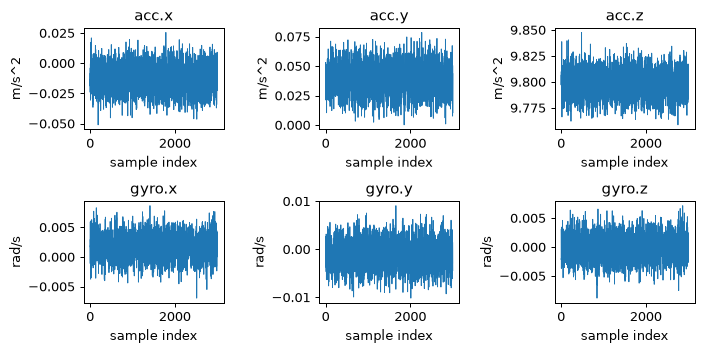

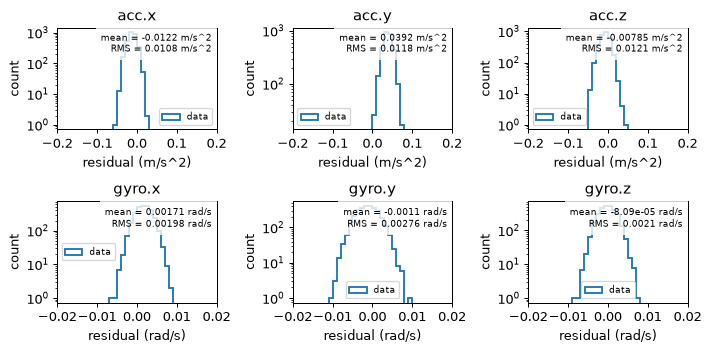

Updated Kalman noise parameters based on this recording: {'kalman.pNAcc_xy': np.float64(0.011312284562458148), 'kalman.pNAcc_z': np.float64(0.012145859652639467), 'kalman.mNGyro_rollpitch': np.float64(0.0023720029023170178), 'kalman.mNGyro_yaw': np.float64(0.002100241625240171)}


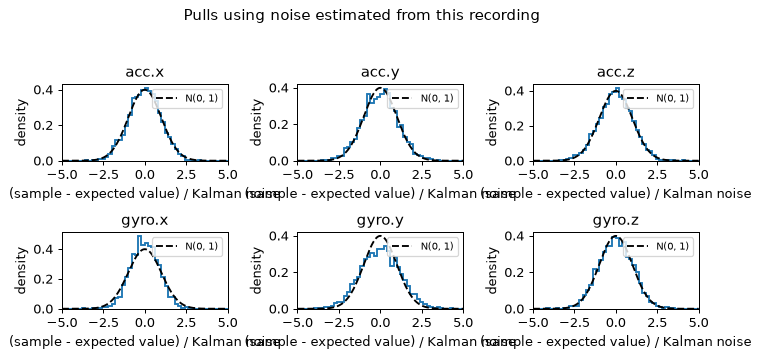

Original and new Kalman noise parameters:
  kalman.pNAcc_xy: 0.5 -> 0.011312284562458148
  kalman.pNAcc_z: 1.0 -> 0.012145859652639467
  kalman.mNGyro_rollpitch: 0.10000000149011612 -> 0.0023720029023170178
  kalman.mNGyro_yaw: 0.10000000149011612 -> 0.002100241625240171


In [6]:
import numpy as np
import matplotlib.pyplot as plt

from day2.notebook_tools import calc_3sigmarms

imu_csv_path = output / "E2B" / "imu.csv"  # Or set this to a copied CSV file.
imu_values = read_imu(imu_csv_path)
imu_values_si = imu_values.astype(float, copy=True)
imu_values_si[:, :3] *= 9.80665  # Accelerometer g -> m/s^2.
imu_values_si[:, 3:] = np.deg2rad(imu_values_si[:, 3:])  # Gyroscope deg/s -> rad/s.

channel_names = [f"{sensor}.{axis}" for sensor in ("acc", "gyro") for axis in "xyz"]
units = ["m/s^2"] * 3 + ["rad/s"] * 3
expected = np.array([0, 0, 9.80665, 0, 0, 0])  # Level, stationary drone in SI units.

def imu_residuals(values_si):
    return values_si - expected

def plot_imu_distributions(values_si):
    means = values_si.mean(axis=0)
    rms = np.sqrt(np.mean(values_si**2, axis=0))
    print("IMU sample mean and RMS:")
    for name, unit, mean, value_rms in zip(channel_names, units, means, rms):
        print(f"{name}: mean={mean:.6g} {unit}, RMS={value_rms:.6g} {unit}")

    figure, axes = plt.subplots(2, 3, figsize=(8, 4))
    for index, axis in enumerate(axes.flat):
        axis.plot(values_si[:, index], linewidth=0.7)
        trace_scale = max(np.std(values_si[:, index]), np.finfo(float).eps)
        #axis.set_yscale("symlog", linthresh=trace_scale)
        axis.set(title=channel_names[index], xlabel="sample index", ylabel=units[index])
    figure.tight_layout()
    plt.show()

    residuals = imu_residuals(values_si)
    residual_means = residuals.mean(axis=0)
    residual_rms = np.sqrt(np.mean(residuals**2, axis=0))
    residual_ranges = [(-0.2, 0.2)] * 3 + [(-0.02, 0.02)] * 3

    # we have some trouble with outliers. the 3sigmarms is a more robust estimator of the RMS than the standard deviation, so we use that to estimate the Kalman noise parameters.
    for i in range(residuals.shape[1]):
        mu,sigma = calc_3sigmarms(residuals[:, i])
        residual_means[i] = mu
        residual_rms[i] = sigma

    figure, axes = plt.subplots(2, 3, figsize=(8, 4))
    for index, axis in enumerate(axes.flat):
        low, high = residual_ranges[index]
        bins = np.linspace(low, high, 41)
        axis.hist(residuals[:, index], bins=bins, histtype="step", linewidth=1.5, label="data")
        if residual_rms[index] > 0:
            normal_x = np.linspace(low, high, 401)
            bin_width = bins[1] - bins[0]
            normal_counts = (
                np.exp(-0.5 * ((normal_x - residual_means[index]) / residual_rms[index]) ** 2)
                / (residual_rms[index] * np.sqrt(2 * np.pi))
                * len(residuals) * bin_width
            )
            #axis.plot(normal_x, normal_counts, "k--", label="normal (sigma = RMS)")
        axis.text(
            0.97, 0.95,
            f"mean = {residual_means[index]:.3g} {units[index]}\nRMS = {residual_rms[index]:.3g} {units[index]}",
            transform=axis.transAxes, ha="right", va="top", fontsize="x-small",
            bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
        )
        axis.set_yscale("log")
        axis.set(title=channel_names[index], xlabel=f"residual ({units[index]})", ylabel="count", xlim=(low, high))
        axis.legend(fontsize="x-small")
    figure.tight_layout()
    plt.show()

    return ({
        "kalman.pNAcc_xy": 0.5 * (residual_rms[0] + residual_rms[1]),
        "kalman.pNAcc_z": residual_rms[2],
        "kalman.mNGyro_rollpitch": 0.5 * (residual_rms[3] + residual_rms[4]),
        "kalman.mNGyro_yaw": residual_rms[5],
    }, residual_means, residual_rms)
 

def plot_imu_pulls(values_si, kalman_noise_values, bias_values, figure_title):
    residuals = imu_residuals(values_si)
    noise = [
        kalman_noise_values["kalman.pNAcc_xy"],
        kalman_noise_values["kalman.pNAcc_xy"],
        kalman_noise_values["kalman.pNAcc_z"],
        kalman_noise_values["kalman.mNGyro_rollpitch"],
        kalman_noise_values["kalman.mNGyro_rollpitch"],
        kalman_noise_values["kalman.mNGyro_yaw"],
    ]
    noise = np.asarray(noise, dtype=float)
    if not np.all(np.isfinite(noise)) or np.any(noise <= 0):
        raise ValueError("Kalman noise values must be finite and greater than zero.")
    pulls = (residuals-bias_values) / noise

    figure, axes = plt.subplots(2, 3, figsize=(8, 4))
    figure.suptitle(figure_title)
    bins = np.linspace(-5, 5, 51)
    normal_x = np.linspace(-5, 5, 401)
    normal_y = np.exp(-0.5 * normal_x**2) / np.sqrt(2 * np.pi)
    for index, axis in enumerate(axes.flat):
        axis.hist(pulls[:, index], bins=bins, density=True, histtype="step", linewidth=1.5)
        axis.plot(normal_x, normal_y, "k--", label="N(0, 1)")
        axis.set(title=channel_names[index], xlabel="(sample - expected value) / Kalman noise", ylabel="density", xlim=(-5, 5))
        #axis.set_yscale("log")
        axis.legend(fontsize="small")
    figure.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()

updated_kalmannoise_values, bias_values, rms = plot_imu_distributions(imu_values_si)
print("Updated Kalman noise parameters based on this recording:", updated_kalmannoise_values)
#plot_imu_pulls(imu_values_si, kalman_noise_values, "Pulls using configured Kalman noise")
plot_imu_pulls(imu_values_si, updated_kalmannoise_values, bias_values,"Pulls using noise estimated from this recording")


print("Original and new Kalman noise parameters:")
for key in kalman_noise_values:
    print(f"  {key}: {kalman_noise_values[key]} -> {updated_kalmannoise_values[key]}")  
  

### Apply the calibration and record a new sample

Run this cell after the first recording and its plots. It uploads the estimated Kalman noise values, verifies them on the drone, records a new 60-second IMU series in `data/<run_id>/E2C/imu.csv`, and plots pulls using the calibrated values and the bias measured from the first series. Keep the drone level and stationary during both recordings. Set `overwrite_calibrated_capture = True` only when you intend to replace an existing E2C recording.


Uploading the noise values estimated from the first recording.
Flight-state check passed (supervisor.info=580).
Current values:
  kalman.pNAcc_xy = 0.5
  kalman.pNAcc_z = 1.0
  kalman.mNGyro_rollpitch = 0.10000000149011612
  kalman.mNGyro_yaw = 0.10000000149011612
kalman.pNAcc_xy: requested 0.011312284562458148, read back 0.011312284506857395
kalman.pNAcc_z: requested 0.012145859652639467, read back 0.012145859189331532
kalman.mNGyro_rollpitch: requested 0.0023720029023170178, read back 0.0023720029275864363
kalman.mNGyro_yaw: requested 0.002100241625240171, read back 0.0021002416033297777
All four Kalman noise parameters match the requested values.
Readback values:
  kalman.pNAcc_xy = 0.011312284506857395
  kalman.pNAcc_z = 0.012145859189331532
  kalman.mNGyro_rollpitch = 0.0023720029275864363
  kalman.mNGyro_yaw = 0.0021002416033297777
STOP VERIFIED: firmware lock set and all four motor outputs zero.
(First attempt lost the radio link: 'Logging failed: connection lost: Too many packe

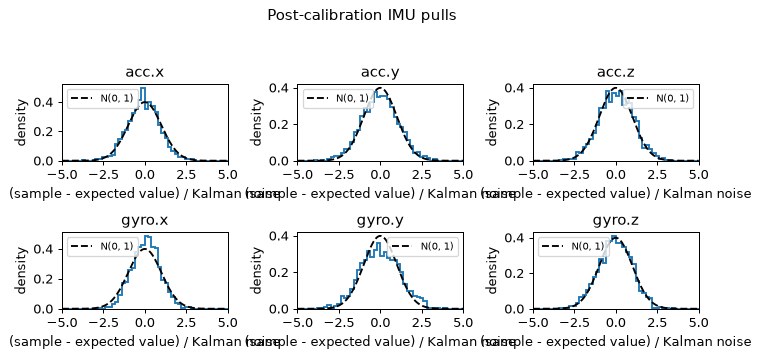

In [7]:
if "uri" not in globals() or not uri:
    raise RuntimeError("Run the Connect cell first.")
if "updated_kalmannoise_values" not in globals() or "bias_values" not in globals():
    raise RuntimeError("Run the first recording and calibration plot cell first.")

print("Uploading the noise values estimated from the first recording.")
update_kalman_noise_parameters(updated_kalmannoise_values)
calibrated_kalman_noise_values = read_kalman_noise_parameters()

calibrated_capture_path = output / "E2C" / "imu_calibrated.csv"
overwrite_calibrated_capture = False  # Set True only to replace an existing E2C recording.
saved_calibrated_imu, calibrated_sample_count = capture(
    uri, calibrated_capture_path,
    channels=channels, duration_s=30, period_ms=20,
    overwrite=overwrite_calibrated_capture,
)
print(f"Saved {calibrated_sample_count} post-calibration samples to {saved_calibrated_imu}")

calibrated_imu_values = read_imu(saved_calibrated_imu)
calibrated_imu_values_si = calibrated_imu_values.astype(float, copy=True)
calibrated_imu_values_si[:, :3] *= 9.80665  # Accelerometer g -> m/s^2.
calibrated_imu_values_si[:, 3:] = np.deg2rad(calibrated_imu_values_si[:, 3:])  # Gyroscope deg/s -> rad/s.
plot_imu_pulls(
    calibrated_imu_values_si,
    calibrated_kalman_noise_values,
    bias_values,
    "Post-calibration IMU pulls",
)


### Apply calibrated parameters before the Day 1 flight

We will now try to fly the drone with the updated parameters. The drone will follow the same path as in the day1/firmware_flight.

The identity and ground-capture cells intentionally engage the firmware motor stop (`stabilizer.stop = 1`), so the propellers cannot spin while you handle the drone. **The first cell below clears it for you** by restarting the drone over the radio (the same as switching it off and on), then uploads the calibrated noise values again, because a restart resets them to the defaults. Do not rerun Connect afterwards: it would engage the stop again.

The second cell flies the drone. It asks you to type `yes` first. Put the drone on the floor in a clear area.

In [8]:
if "uri" not in globals() or not uri:
    raise RuntimeError("Run the Connect cell before the ground measurements.")
if "updated_kalmannoise_values" not in globals():
    raise RuntimeError("Run the calibration plot cell to calculate the calibrated values first.")

from day1 import crazyflie

# Clear the motor stop: a radio restart is the same as switching the drone off and on.
print("Restarting the drone to clear the motor stop...")
crazyflie.reboot(uri, settle=4.0)
cflib.crtp.init_drivers()
with SyncCrazyflie(uri, cf=Crazyflie(rw_cache='./cache')) as scf:
    scf.wait_for_params()
    stop = int(scf.cf.param.get_value("stabilizer.stop", timeout=5.0))
if stop != 0:
    raise RuntimeError("The motor stop is still on: switch the drone off and on by hand, then rerun this cell.")
print("Motor stop cleared (stabilizer.stop = 0).")

# The restart reset the noise values to the defaults: upload the calibrated ones again.
flight_kalman_noise_values = update_kalman_noise_parameters(updated_kalmannoise_values)
read_kalman_noise_parameters()
print("Calibrated values are loaded for this powered session. Continue to the Day 1 preflight and flight cell.")


Restarting the drone to clear the motor stop...
Motor stop cleared (stabilizer.stop = 0).
Flight-state check passed (supervisor.info=526).
(upload readback: the four calibrated values above, all matching)
Calibrated values are loaded for this powered session. Continue to the Day 1 preflight and flight cell.


In [9]:
# let's try to fly the drone
from day1 import crazyflie

if input("Drone on the floor, area clear, someone ready to abort? Type yes to fly: ").strip().lower() != "yes":
    raise SystemExit("Flight cancelled.")

with crazyflie.connect(uri) as scf:
    crazyflie.status(scf)

#crazyflie.bench_test_abort()

PATH = [('forward', 0.5), ('hold', 2.0), ('back', 0.5)]

run = crazyflie.fly_path(PATH, uri=uri, speed=0.3)
name = crazyflie.save(run, 'firmware_fwd')


Drone on the floor, area clear, someone ready to abort? Type yes to fly: yes
Drone status of radio://0/30/2M/E7E7E7E704
  battery      : in use, 3.92 V at rest, 50 % of a full charge
  flight       : ok
  flow deck    : attached
  can be armed : no
  is armed     : yes
  is tumbled   : no
  is locked    : no
  height       : estimate 0.013 m, sensor 0.011 m, agree
  position     : estimate moved 0.004 m in 2 s on the ground, ok
[ 2.2 s] connected, estimator reset, 1.5 s watching the estimate on the ground
[ 3.8 s] deck ok, armed, take-off to 0.50 m
[ 8.4 s] in the air, 2.0 s to settle at hover
[10.4 s] path starts at x 0.11 m, y -0.01 m: forward 0.5, hold 2, back 0.5
[19.3 s] landing
path completed
loop iterations: 420  logged rows: {'state': 1034, 'sensor': 1034, 'power': 413, 'land': 1034}
saved data/flight_4_1304_firmware_fwd_state.csv
saved data/flight_4_1304_firmware_fwd_sensor.csv
saved data/flight_4_1304_firmware_fwd_power.csv
saved data/flight_4_1304_firmware_fwd_land.csv
saved

Continue with [03 height and velocity](03_height_velocity.ipynb). E3 estimates acceleration offset and range precision from initial rest; E6 tests those frozen values on fresh data.
